# Assignment 6

Same experiment - different representation. Dataset contains same data, but it uses vgg16 embeddings instead of handcrafted morpho characteristics. 
>week6\large_object_vgg3d_embeddings_processed.csv

## Task

Build and evaluate a neural-network classifier for `cell_type` using the VGG3D embedding representation. Compare it with at least one simpler model and explain what the results mean biologically and statistically.

Do not use `sample_group` as a predictive feature. Use it only to construct leakage-safe splits.

## Required sections

## Questions for the report

1. Did the embedding space show visible separation between the cell types?
2. Which learning rate and architecture performed best, and what evidence supports that choice?
3. Did the MLP overfit? Use the training and validation curves to justify your answer.
4. Which regularization method was most useful?
5. How did the MLP compare with logistic regression and XGBoost?
7. Which cell types were most frequently confused?
8. What additional biological or technical information would help explain the errors?

## Deliverables

- completed notebook;
- short report answering the questions above;
- one table comparing the final models;
- figures for the embedding visualization, learning curves, and confusion matrix;
- a brief statement of limitations and possible next steps.

In [70]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import optuna
import torch
import torch.nn as nn
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    GroupShuffleSplit,
    PredefinedSplit,
    StratifiedGroupKFold,
)
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from torch.utils.data import DataLoader, TensorDataset
from xgboost import XGBClassifier
import plotly.express as px
from sklearn.pipeline import make_pipeline
from torch.utils.data import TensorDataset, DataLoader

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEVICE)


Device: cuda


### 1. Data inspection and preparation checklist

Since data is the same no need to write detailed report but still - check if everything is in order(just in case)

In [71]:
df = pd.read_csv("large_object_vgg3d_embeddings_processed.csv")
df.head()


,cell_type,sample_group,vgg_emb_000,vgg_emb_001,vgg_emb_002,vgg_emb_003,vgg_emb_004,vgg_emb_005,vgg_emb_006,vgg_emb_007,...,vgg_emb_118,vgg_emb_119,vgg_emb_120,vgg_emb_121,vgg_emb_122,vgg_emb_123,vgg_emb_124,vgg_emb_125,vgg_emb_126,vgg_emb_127
0,m0,sample_group_079,0.039772,0.0,1.179048,0.0,0.0,0.0,1.221995,0.0,...,0.0,0.0,0.0,0.797191,1.709197,0.0,0.777199,0.0,1.924863,0.0
1,m0,sample_group_079,0.000000,0.0,4.433527,0.0,0.0,0.0,5.810353,0.0,...,0.0,0.0,0.0,3.935624,6.289729,0.0,2.987612,0.0,8.424339,0.0
2,m0,sample_group_079,0.000000,0.0,4.108049,0.0,0.0,0.0,5.343654,0.0,...,0.0,0.0,0.0,3.621442,5.779456,0.0,2.740911,0.0,7.669261,0.0
3,m0,sample_group_079,0.000000,0.0,4.042331,0.0,0.0,0.0,5.283560,0.0,...,0.0,0.0,0.0,3.587561,5.783239,0.0,2.660382,0.0,7.480461,0.0
4,m0,sample_group_079,0.000000,0.0,2.474535,0.0,0.0,0.0,3.063431,0.0,...,0.0,0.0,0.0,2.021839,3.586300,0.0,1.637182,0.0,4.486126,0.0


In [72]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Columns: 130 entries, cell_type to vgg_emb_127
dtypes: float64(128), str(2)
memory usage: 393.8 KB


In [73]:
df.isna().sum().sum()


np.int64(0)

In [74]:
CELL_TYPE = "cell_type"
SAMPLE_GROUP = "sample_group"

features = df.columns[~df.columns.isin([CELL_TYPE, SAMPLE_GROUP])]
features


Index(['vgg_emb_000', 'vgg_emb_001', 'vgg_emb_002', 'vgg_emb_003',
       'vgg_emb_004', 'vgg_emb_005', 'vgg_emb_006', 'vgg_emb_007',
       'vgg_emb_008', 'vgg_emb_009',
       ...
       'vgg_emb_118', 'vgg_emb_119', 'vgg_emb_120', 'vgg_emb_121',
       'vgg_emb_122', 'vgg_emb_123', 'vgg_emb_124', 'vgg_emb_125',
       'vgg_emb_126', 'vgg_emb_127'],
      dtype='str', length=128)

In [75]:
features = features[~df[features].std().eq(0)]
features.size


91

In [76]:
X = df[features]
X.head()


,vgg_emb_000,vgg_emb_002,vgg_emb_005,vgg_emb_006,vgg_emb_008,vgg_emb_009,vgg_emb_010,vgg_emb_011,vgg_emb_012,vgg_emb_013,...,vgg_emb_113,vgg_emb_114,vgg_emb_116,vgg_emb_117,vgg_emb_121,vgg_emb_122,vgg_emb_124,vgg_emb_125,vgg_emb_126,vgg_emb_127
0,0.039772,1.179048,0.0,1.221995,1.287161,0.0,0.0,0.0,0.328466,1.796104,...,0.0,1.772306,0.295292,0.893132,0.797191,1.709197,0.777199,0.0,1.924863,0.0
1,0.000000,4.433527,0.0,5.810353,5.679070,0.0,0.0,0.0,1.328905,6.663649,...,0.0,7.227830,0.385759,3.204363,3.935624,6.289729,2.987612,0.0,8.424339,0.0
2,0.000000,4.108049,0.0,5.343654,5.157644,0.0,0.0,0.0,1.135407,6.089701,...,0.0,6.589556,0.342752,2.966972,3.621442,5.779456,2.740911,0.0,7.669261,0.0
3,0.000000,4.042331,0.0,5.283560,5.123363,0.0,0.0,0.0,1.147058,6.012712,...,0.0,6.451838,0.318679,2.946192,3.587561,5.783239,2.660382,0.0,7.480461,0.0
4,0.000000,2.474535,0.0,3.063431,3.048964,0.0,0.0,0.0,0.752677,3.735067,...,0.0,3.997463,0.349789,1.817329,2.021839,3.586300,1.637182,0.0,4.486126,0.0


In [77]:
y = df[CELL_TYPE]
y.head()


0    m0
1    m0
2    m0
3    m0
4    m0
Name: cell_type, dtype: str

In [78]:
groups = df[SAMPLE_GROUP]
groups.head()


0    sample_group_079
1    sample_group_079
2    sample_group_079
3    sample_group_079
4    sample_group_079
Name: sample_group, dtype: str

### 2. Exploratory analysis

Show:

- class counts for `m0`, `m1`, and `m2`;
- the distribution of selected embedding features;
- missingness by feature and by row;
- a two-dimensional t-SNE or UMAP visualization coloured by `cell_type`.

Treat t-SNE/UMAP as exploratory visualizations, not as test-set evaluation.

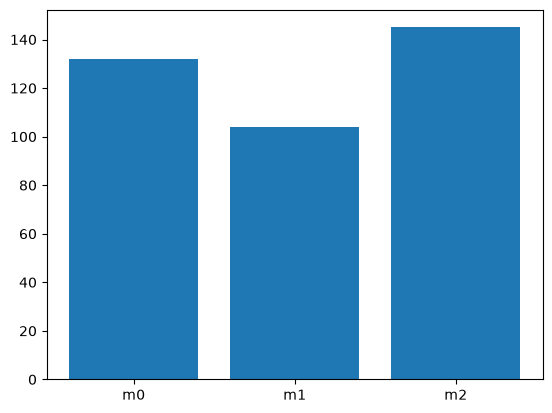

In [79]:
counts = y.value_counts().sort_index()
plt.bar(counts.index, counts)
plt.show()


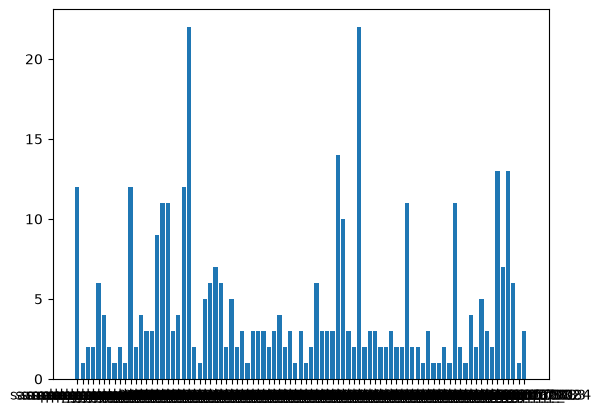

In [80]:
counts = groups.value_counts().sort_index()
plt.bar(counts.index, counts)
plt.show()


In [81]:
stats = pd.DataFrame({
  "mean": X.mean(),
  "var": X.var(),
})

fig = px.scatter(
  stats.reset_index(names="feature"),
  x="mean", y="var",
  hover_name="feature",
  labels={"mean": "Mean", "var": "Variance"},
  title="Mean vs variance per feature",
)

fig.show()


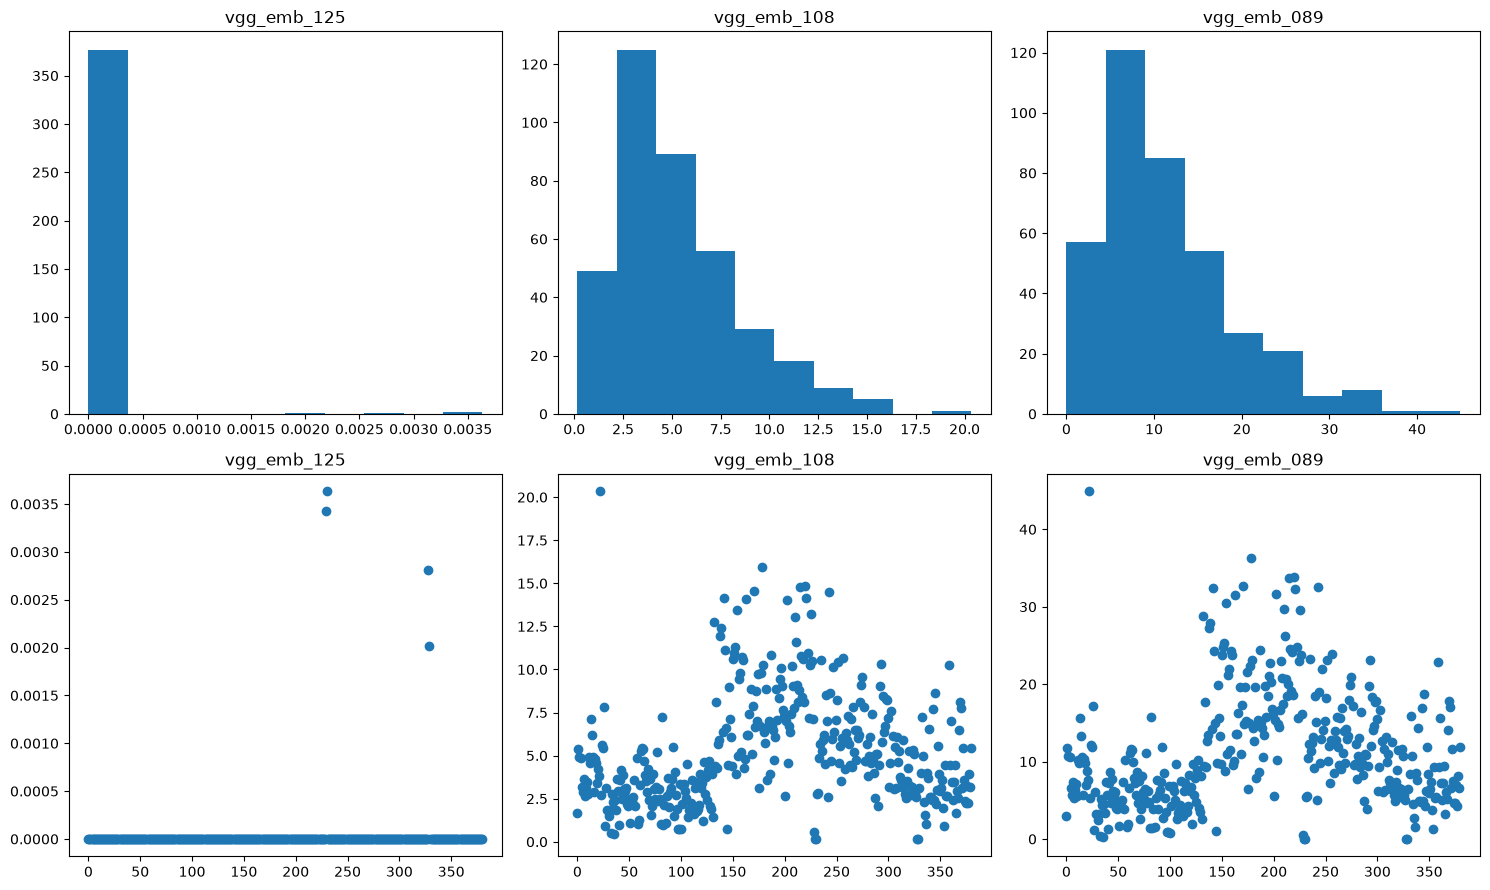

In [82]:
fig, axs = plt.subplots(ncols=3, nrows=2, figsize=(15, 9))

def plot_feature(n, feature):
  axs[0][n].hist(X[feature])
  axs[0][n].set_title(feature)

  axs[1][n].scatter(X.index, X[feature])
  axs[1][n].set_title(feature)

plot_feature(0, 'vgg_emb_125')
plot_feature(1, 'vgg_emb_108')
plot_feature(2, 'vgg_emb_089')

fig.tight_layout()
plt.show()


In [83]:
X_scaled = StandardScaler().fit_transform(X)

tsne = TSNE(
  n_components=2, perplexity=30, init="pca",
  learning_rate="auto", random_state=RANDOM_STATE,
)
X_tsne = tsne.fit_transform(X_scaled)
tsne_df = pd.DataFrame(X_tsne, columns=["tSNE1", "tSNE2"], index=X.index).join(y).join(groups)


In [84]:
fig = px.scatter(
  tsne_df.reset_index(), x="tSNE1", y="tSNE2", color=CELL_TYPE,
  hover_name=tsne_df.index.name or "index",
  title=f"t-SNE colored by {CELL_TYPE}",
  opacity=0.8,
  width=600, height=500,
)
fig.update_traces(marker_size=10)
fig.show()


In [85]:
fig = px.scatter(
  tsne_df.reset_index(), x="tSNE1", y="tSNE2", color=SAMPLE_GROUP,
  hover_name=tsne_df.index.name or "index",
  title=f"t-SNE colored by {SAMPLE_GROUP}",
  opacity=0.8,
  width=600, height=500,
)
fig.update_traces(marker_size=10)
fig.show()


### 3. Leakage-safe splitting and preprocessing

Create training, validation, and test partitions, be sure that you dont introduce any leakege.

In [86]:
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
split = outer.split(X, y, groups)
trainval_idx, test_idx = next(split)

inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
split = inner.split(X.iloc[trainval_idx], y.iloc[trainval_idx], groups.iloc[trainval_idx])
tr, va = next(split)
train_idx, val_idx = trainval_idx[tr], trainval_idx[va]

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val,   y_val   = X.iloc[val_idx],   y.iloc[val_idx]
X_test,  y_test  = X.iloc[test_idx],  y.iloc[test_idx]


In [87]:
g_tr, g_va, g_te = (set(groups.iloc[i]) for i in (train_idx, val_idx, test_idx))
assert not (g_tr & g_va or g_tr & g_te or g_va & g_te)

pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "val":   y_val.value_counts(normalize=True),
    "test":  y_test.value_counts(normalize=True),
}).sort_index()


,train,val,test
cell_type,,,
m0,0.348018,0.337662,0.350649
m1,0.273128,0.272727,0.272727
m2,0.378855,0.389610,0.376623


### 4. Baseline and MLP model

Train a simple baseline, such as multinomial logistic regression, followed by a PyTorch MLP

Report training and validation loss and accuracy across epochs.

In [88]:
logreg = make_pipeline(
  StandardScaler(),
  LogisticRegression(class_weight="balanced", random_state=RANDOM_STATE),
)

logreg.fit(X_train, y_train)
acc_val = balanced_accuracy_score(y_val, logreg.predict(X_val))
acc_test = balanced_accuracy_score(y_test, logreg.predict(X_test))

print(f"Validation weighted accuracy: {acc_val}")
print(f"Test weighted accuracy: {acc_test}")


Validation weighted accuracy: 0.5794871794871795
Test weighted accuracy: 0.7456060329623547


In [89]:
CLASSES = np.sort(y.unique())

class Scaler(nn.Module):
  def __init__(self, n_features, eps=1e-8):
    super().__init__()
    self.eps = eps
    self.register_buffer("mean", torch.zeros(n_features))
    self.register_buffer("std", torch.ones(n_features))

  @torch.no_grad()
  def fit(self, X):
    X = torch.from_numpy(X.values)
    std = X.std(dim=0, unbiased=False)
    self.mean.copy_(X.mean(dim=0))
    self.std.copy_(torch.where(std < self.eps, torch.ones_like(std), std))
    return self

  def forward(self, X):
    return (X - self.mean) / self.std

class MLP(nn.Module):
  def __init__(self, input_dim, n_classes, hidden=(32, 16), dropout=False):
    super().__init__()
    torch.manual_seed(RANDOM_STATE)
    layers = [Scaler(input_dim).fit(X_train)]

    for h in hidden:
      layers += [nn.Linear(input_dim, h), nn.ReLU()]
      input_dim = h

    if dropout:
      layers.append(nn.Dropout(p=0.3))

    layers.append(nn.Linear(input_dim, n_classes))
    self.network = nn.Sequential(*layers)

  def forward(self, x):
    return self.network(x)

model = MLP(X_train.shape[1], n_classes=CLASSES.size).to(DEVICE)
print(model)


MLP(
  (network): Sequential(
    (0): Scaler()
    (1): Linear(in_features=91, out_features=32, bias=True)
    (2): ReLU()
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Linear(in_features=16, out_features=3, bias=True)
  )
)


In [90]:
BATCH_SIZE = 32

def to_dataset(X, y):
  X_t = torch.tensor(X.to_numpy(), dtype=torch.float32)
  y_t = torch.tensor(pd.Categorical(y, categories=CLASSES).codes, dtype=torch.long)
  return TensorDataset(X_t, y_t)

train_ds = to_dataset(X_train, y_train)
val_ds = to_dataset(X_val, y_val)
test_ds = to_dataset(X_test, y_test)

train_loader = DataLoader(
  train_ds, batch_size=BATCH_SIZE, shuffle=True,
  generator=torch.Generator().manual_seed(RANDOM_STATE),
)

val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)

xb, yb = next(iter(train_loader))
print(f"train: {len(train_ds)} rows, {len(train_loader)} batches | val: {len(val_ds)} rows, {len(val_loader)} batches | test: {len(test_ds)} rows,  {len(test_loader)} batches")


train: 227 rows, 8 batches | val: 77 rows, 3 batches | test: 77 rows,  3 batches


In [91]:
def train_one_epoch(model, loader, criterion, optimizer, device):
  model.train()

  total_loss = 0.0
  all_preds, all_targets = [], []

  for X_batch, y_batch in loader:
    X_batch = X_batch.to(device)
    y_batch = y_batch.to(device)

    optimizer.zero_grad()
    logits = model(X_batch)
    loss = criterion(logits, y_batch)
    loss.backward()
    optimizer.step()

    total_loss += loss.item() * X_batch.size(0)
    pred = logits.argmax(dim=1).cpu()
    all_preds.append(pred)
    all_targets.append(y_batch.cpu())

  y_true = torch.cat(all_targets).numpy()
  y_pred = torch.cat(all_preds).numpy()

  return (
    total_loss / y_pred.shape[0],
    balanced_accuracy_score(y_true, y_pred),
  )

@torch.no_grad()
def evaluate(model, loader, criterion, device):
  model.eval()

  total_loss = 0.0
  all_preds, all_targets = [], []

  for X_batch, y_batch in loader:
    X_batch = X_batch.to(device)
    y_batch = y_batch.to(device)

    logits = model(X_batch)
    loss = criterion(logits, y_batch)
    total_loss += loss.item() * X_batch.size(0)
    pred = logits.argmax(dim=1).cpu()

    all_preds.append(pred)
    all_targets.append(y_batch.cpu())

  y_true = torch.cat(all_targets).numpy()
  y_pred = torch.cat(all_preds).numpy()

  return (
    total_loss / y_pred.shape[0],
    balanced_accuracy_score(y_true, y_pred),
  )


In [92]:
N_EPOCHS = 50
LR=1e-3

def train(model: nn.Module, lr=LR, weight_decay=0, n_epoch=N_EPOCHS, patience=-1, log=True):
  history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
  criterion = nn.CrossEntropyLoss()
  optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
  train_loader.generator.manual_seed(RANDOM_STATE)

  best_loss, best_state, best_epoch = float('inf'), None, -1
  patience = n_epoch if patience == -1 else patience
  wait = 0

  for epoch in range(n_epoch):
    train_loss, train_acc = train_one_epoch(
      model,
      train_loader,
      criterion,
      optimizer,
      DEVICE,
    )

    val_loss, val_acc = evaluate(
      model,
      val_loader,
      criterion,
      DEVICE,
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if log and (epoch + 1) % 5 == 0:
      print(
        f"Epoch {epoch+1:03d} | "
        f"train loss={train_loss:.4f} | "
        f"val loss={val_loss:.4f} | "
        f"train acc={train_acc:.3f} | "
        f"val acc={val_acc:.3f}"
      )

    if val_loss < best_loss - 1e-4:
      best_loss = val_loss
      best_state = copy.deepcopy(model.state_dict())
      best_epoch = epoch
      wait = 0
    else:
      wait += 1
      if wait >= patience:
        if log:
          print(f"Early stopping at epoch {epoch+1:03d}")
          print(f"Best epoch={best_epoch+1:03d} | best val_loss={best_loss:.4f}")
        break

  if wait >= patience:
    model = model.load_state_dict(best_state)

  return model, history

def plot_history(history, acc_baseline, labels=None):
  histories = history if isinstance(history, list) else [history]
  if labels is None:
    labels = [None] * len(histories)
  assert len(labels) == len(histories), "need one label per history"

  fig, axs = plt.subplots(ncols=2, figsize=(14, 4))

  for i, (hist, label) in enumerate(zip(histories, labels)):
    prefix = f"{label} " if label is not None else ""
    for ax, metric in zip(axs, ("loss", "acc")):
      ax.plot(hist[f"train_{metric}"], color=f"C{i}", linestyle="-", label=f"{prefix}train")
      ax.plot(hist[f"val_{metric}"], color=f"C{i}", linestyle="--", label=f"{prefix}validation")

  axs[0].set_xlabel("epoch")
  axs[0].set_ylabel("loss")
  axs[0].legend()

  axs[1].axhline(acc_baseline, color="red", linestyle=":", label=f"LogReg val ({acc_baseline:.3f})")
  axs[1].set_xlabel("epoch")
  axs[1].set_ylabel("balanced accuracy")
  axs[1].legend()

  fig.tight_layout()
  plt.show()


Epoch 005 | train loss=0.9493 | val loss=1.0047 | train acc=0.573 | val acc=0.540
Epoch 010 | train loss=0.8464 | val loss=0.9776 | train acc=0.608 | val acc=0.594
Epoch 015 | train loss=0.8067 | val loss=0.9201 | train acc=0.628 | val acc=0.641
Epoch 020 | train loss=0.7731 | val loss=0.9076 | train acc=0.637 | val acc=0.679
Epoch 025 | train loss=0.7513 | val loss=0.9042 | train acc=0.638 | val acc=0.690
Epoch 030 | train loss=0.7356 | val loss=0.9069 | train acc=0.646 | val acc=0.645
Epoch 035 | train loss=0.7311 | val loss=0.9045 | train acc=0.651 | val acc=0.647
Epoch 040 | train loss=0.7305 | val loss=0.9575 | train acc=0.659 | val acc=0.552
Epoch 045 | train loss=0.7133 | val loss=0.9511 | train acc=0.671 | val acc=0.589
Epoch 050 | train loss=0.7014 | val loss=0.9655 | train acc=0.685 | val acc=0.567


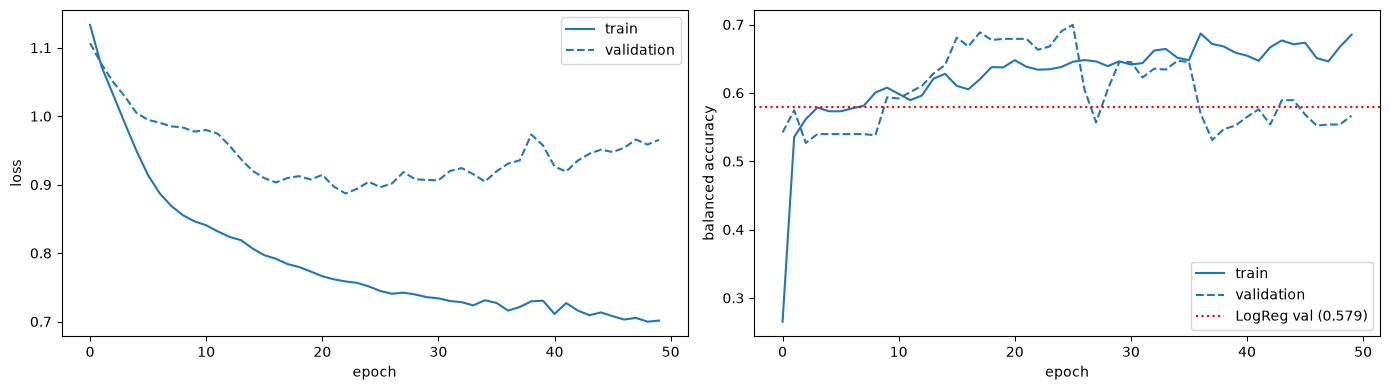

In [93]:
model = MLP(X_train.shape[1], n_classes=CLASSES.size).to(DEVICE)
_, history = train(model)
plot_history(history, acc_baseline=acc_val)


### 5. Experiments

Perform experiments corresponding to the Week 6 explanations:

- compare at least three learning rates;
- compare at least two network capacities;
- identify possible overfitting from learning curves;
- compare weight decay and dropout;
- demonstrate early stopping;
- explain which configuration you select and why.

Keep the random seed fixed when comparing configurations.

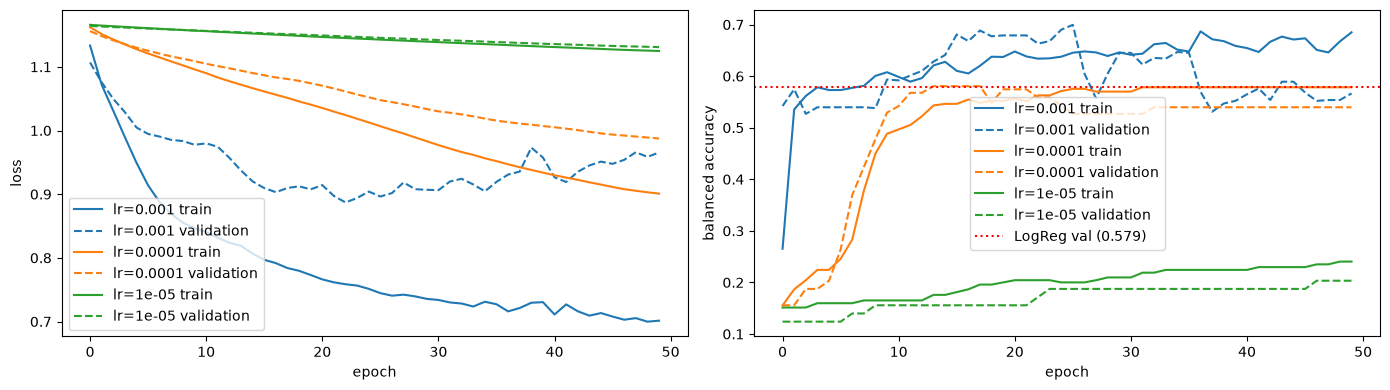

In [94]:
lrs = [1e-3, 1e-4, 1e-5]

histories_lr = []
for lr in lrs:
  model = MLP(X_train.shape[1], n_classes=CLASSES.size).to(DEVICE)
  _, hist = train(model, lr, log=False)
  hist["lr"] = lr
  histories_lr.append(hist)

plot_history(histories_lr, acc_baseline=acc_val, labels=[f"lr={lr:g}" for lr in lrs])


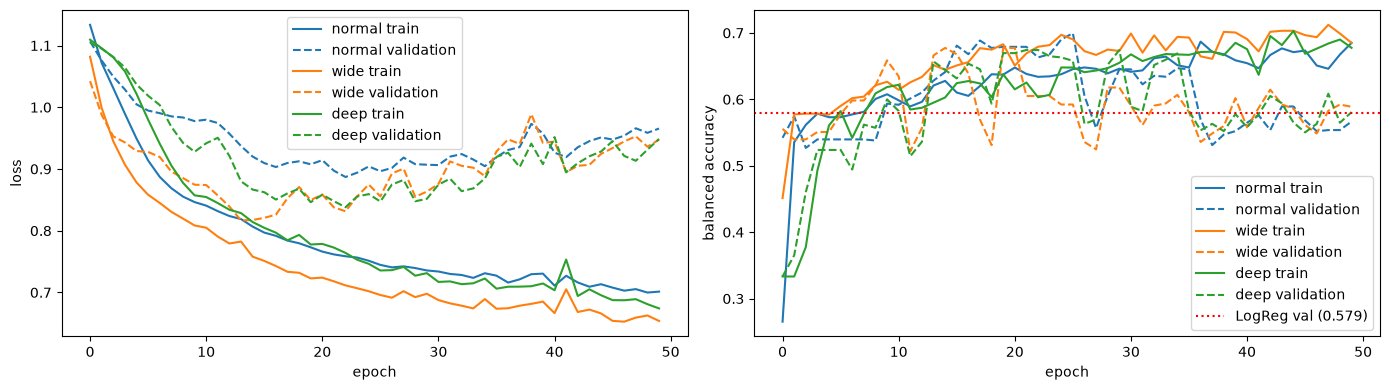

In [95]:
histories_cap = { "normal": histories_lr[0] }

model_wide = MLP(
  X_train.shape[1],
  n_classes=CLASSES.size,
  hidden=(64, 32)
).to(DEVICE)

_, hist = train(model_wide, log=False)
histories_cap["wide"] = hist

model_deep = MLP(
  X_train.shape[1],
  n_classes=CLASSES.size,
  hidden=(32, 32, 32, 16)
).to(DEVICE)

_, hist = train(model_deep, log=False)
histories_cap["deep"] = hist

plot_history(list(histories_cap.values()), acc_baseline=acc_val, labels=list(histories_cap))


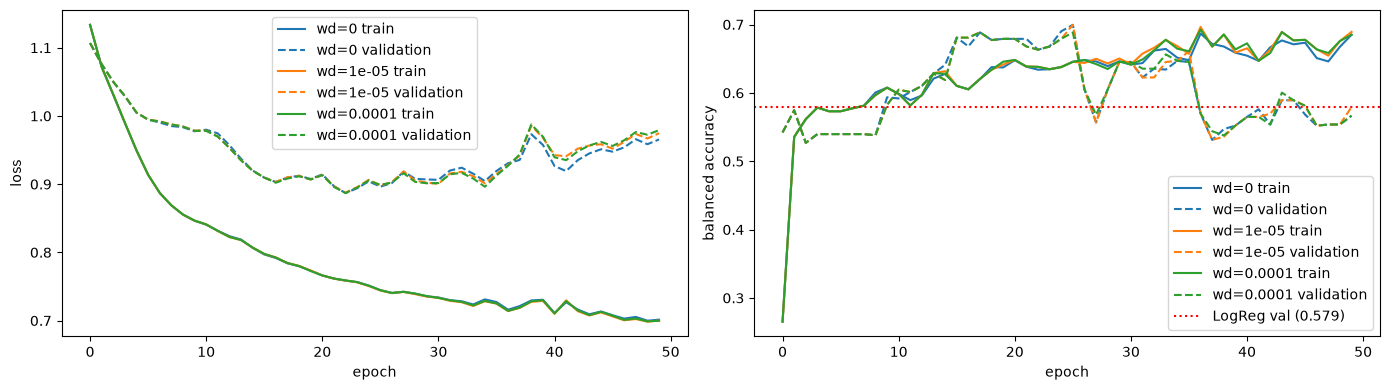

In [96]:
weight_decay = [0.0, 1e-5, 1e-4]

histories_wd = []
for wd in weight_decay:
  model = MLP(X_train.shape[1], n_classes=CLASSES.size).to(DEVICE)
  _, hist = train(model, weight_decay=wd, log=False)
  hist["wd"] = wd
  histories_wd.append(hist)

plot_history(histories_wd, acc_baseline=acc_val, labels=[f"wd={wd:g}" for wd in weight_decay])


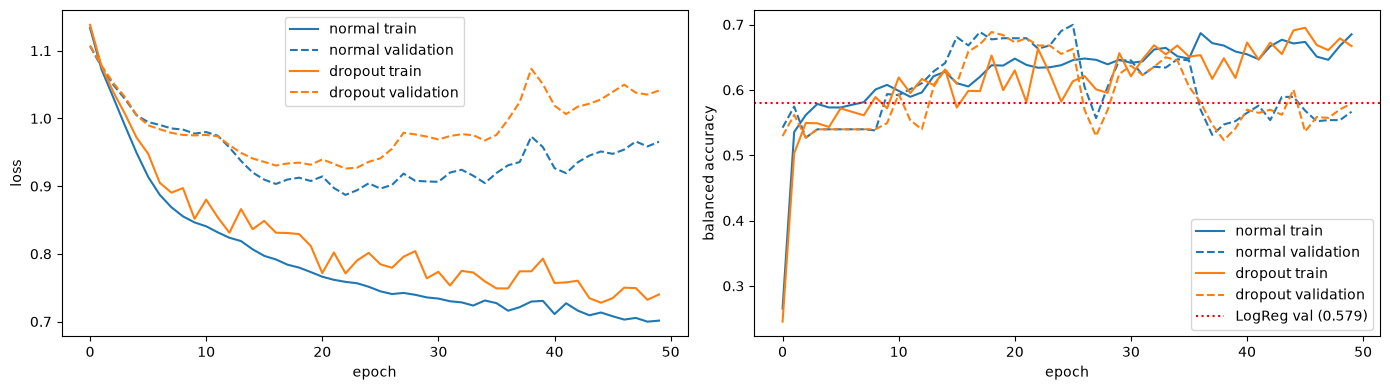

In [97]:
histories_dropout = { "normal": histories_lr[0] }

model_dropout = MLP(
  X_train.shape[1],
  n_classes=CLASSES.size,
  dropout=True,
).to(DEVICE)

_, hist = train(model_dropout, log=False)
histories_dropout["dropout"] = hist

plot_history(list(histories_dropout.values()), acc_baseline=acc_val, labels=list(histories_dropout))


The default configuration of the model seems to be the optimal configuration for the task. Wide and deep models perform roughly the same but have less stable loss curve. Lower LR while don't reach overfitting point also learn much slower than 1e-3. Weight decay doesn't have an influence at all. Dropout performs poor, making the loss curve more rough.

The only real improvement comes from early stopping - stopping training before the model starts to overfit.

Epoch 005 | train loss=0.9493 | val loss=1.0047 | train acc=0.573 | val acc=0.540
Epoch 010 | train loss=0.8464 | val loss=0.9776 | train acc=0.608 | val acc=0.594
Epoch 015 | train loss=0.8067 | val loss=0.9201 | train acc=0.628 | val acc=0.641
Epoch 020 | train loss=0.7731 | val loss=0.9076 | train acc=0.637 | val acc=0.679
Early stopping at epoch 020
Best epoch=017 | best val_loss=0.9032


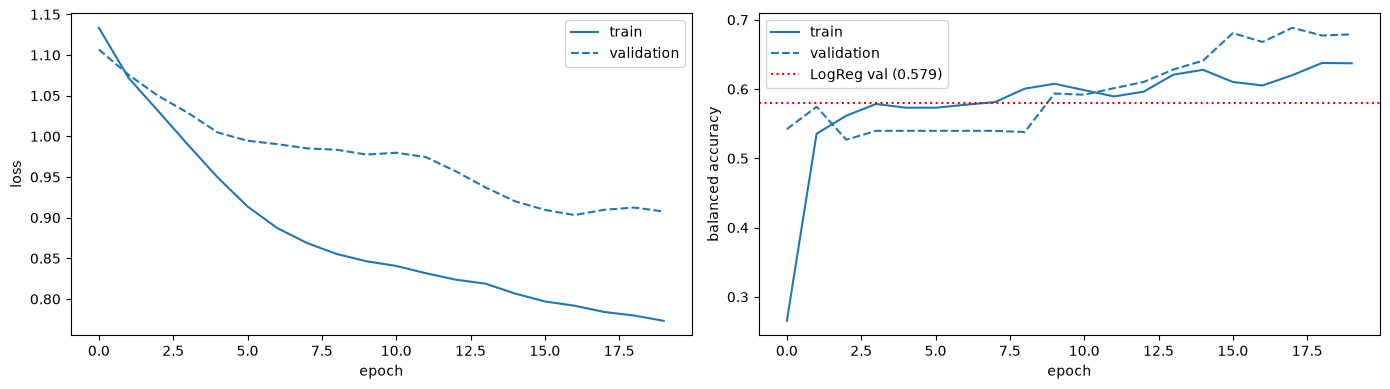

In [98]:
final_model = MLP(X_train.shape[1], n_classes=CLASSES.size).to(DEVICE)
_, history = train(final_model, patience=3)
plot_history(history, acc_baseline=acc_val)


### 6. Classical comparison

Compare the selected MLP with:

- logistic regression;
- XGBoost with a small, validation-only hyperparameter search.

In [99]:
y_train_codes = pd.Categorical(y_train, categories=CLASSES).codes
y_val_codes = pd.Categorical(y_val, categories=CLASSES).codes
y_test_codes = pd.Categorical(y_test, categories=CLASSES).codes

# validation-only search: fit on train, score on val
X_trval = pd.concat([X_train, X_val])
y_trval = np.concatenate([y_train_codes, y_val_codes])
test_fold = np.concatenate([
  np.full(len(X_train), -1),  # train rows: never scored
  np.full(len(X_val), 0),     # val rows: the single scoring fold
])
val_split = PredefinedSplit(test_fold)

param_grid = {
  "max_depth": [2, 3, 4],
  "learning_rate": [0.05, 0.1],
  "n_estimators": [100, 300],
}

xgb_search = GridSearchCV(
  XGBClassifier(
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
  ),
  param_grid,
  scoring="balanced_accuracy",
  cv=val_split,
  refit=False,
)
xgb_search.fit(X_trval, y_trval)

# refit on train only, so val stays held out like for LogReg and MLP
best_xgb = XGBClassifier(
  **xgb_search.best_params_,
  subsample=0.8,
  colsample_bytree=0.8,
  objective="multi:softprob",
  eval_metric="mlogloss",
  random_state=RANDOM_STATE,
).fit(X_train, y_train_codes)

print("Best params:", xgb_search.best_params_)
pd.DataFrame(xgb_search.cv_results_)[["params", "mean_test_score"]] \
  .sort_values("mean_test_score", ascending=False).head()


Best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300}


,params,mean_test_score
3,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.585836
1,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.584127
5,"{'learning_rate': 0.05, 'max_depth': 4, 'n_est...",0.574725
0,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.558852
2,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.558852


### 7. Evaluation

Evaluate the final selected models on the untouched test partition using:

- balanced accuracy;
- macro F1 score;
- a confusion matrix;
- a short class-by-class error analysis.

Do not select the final model using test performance.

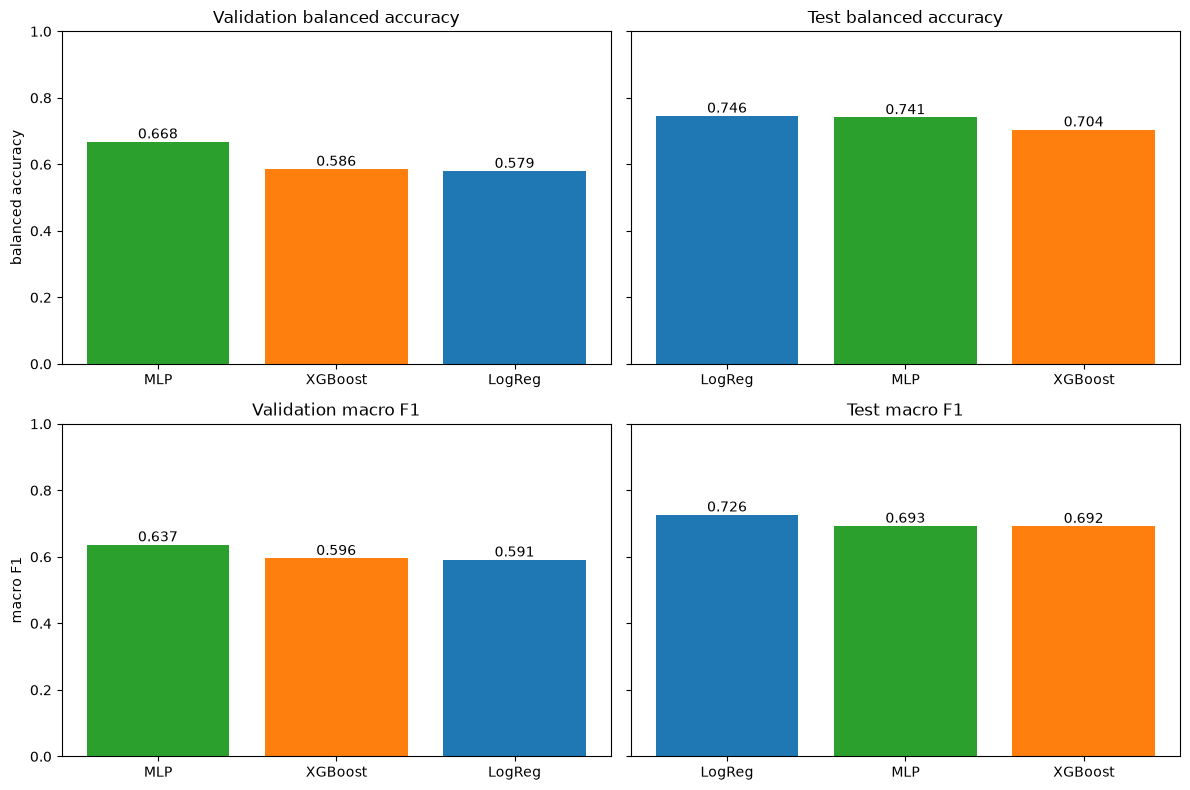

balanced accuracy             macro F1           
split                test validation      test validation
model                                                    
LogReg           0.745606   0.579487  0.726496   0.591027
MLP              0.741045   0.668010  0.692788   0.636693
XGBoost          0.704190   0.585836  0.692171   0.595692

In [ ]:
@torch.no_grad()
def predict_mlp(model, loader):
  model.eval()
  return torch.cat([model(X_batch.to(DEVICE)).argmax(dim=1).cpu() for X_batch, _ in loader]).numpy()

predictions = {
  "LogReg": {
    "validation": pd.Categorical(logreg.predict(X_val), categories=CLASSES).codes,
    "test": pd.Categorical(logreg.predict(X_test), categories=CLASSES).codes,
  },
  "XGBoost": {
    "validation": best_xgb.predict(X_val),
    "test": best_xgb.predict(X_test),
  },
  "MLP": {
    "validation": predict_mlp(final_model, val_loader),
    "test": predict_mlp(final_model, test_loader),
  },
}
targets = {"validation": y_val_codes, "test": y_test_codes}

comparison = pd.DataFrame([
  {
    "model": name,
    "split": split,
    "balanced accuracy": balanced_accuracy_score(targets[split], pred),
    "macro F1": f1_score(targets[split], pred, average="macro"),
  }
  for name, preds in predictions.items()
  for split, pred in preds.items()
]).pivot(index="model", columns="split")

colors = {name: f"C{i}" for i, name in enumerate(predictions)}
metrics = ["balanced accuracy", "macro F1"]
splits = ["validation", "test"]

fig, axs = plt.subplots(nrows=len(metrics), ncols=len(splits), figsize=(12, 8), sharey=True)

for row, metric in zip(axs, metrics):
  for ax, split in zip(row, splits):
    scores = comparison[(metric, split)].sort_values(ascending=False)
    bars = ax.bar(scores.index, scores, color=[colors[m] for m in scores.index])
    ax.bar_label(bars, fmt="%.3f")
    ax.set_title(f"{split.capitalize()} {metric}")
    ax.set_ylim(0, 1)
  row[0].set_ylabel(metric)

fig.tight_layout()
plt.show()

comparison


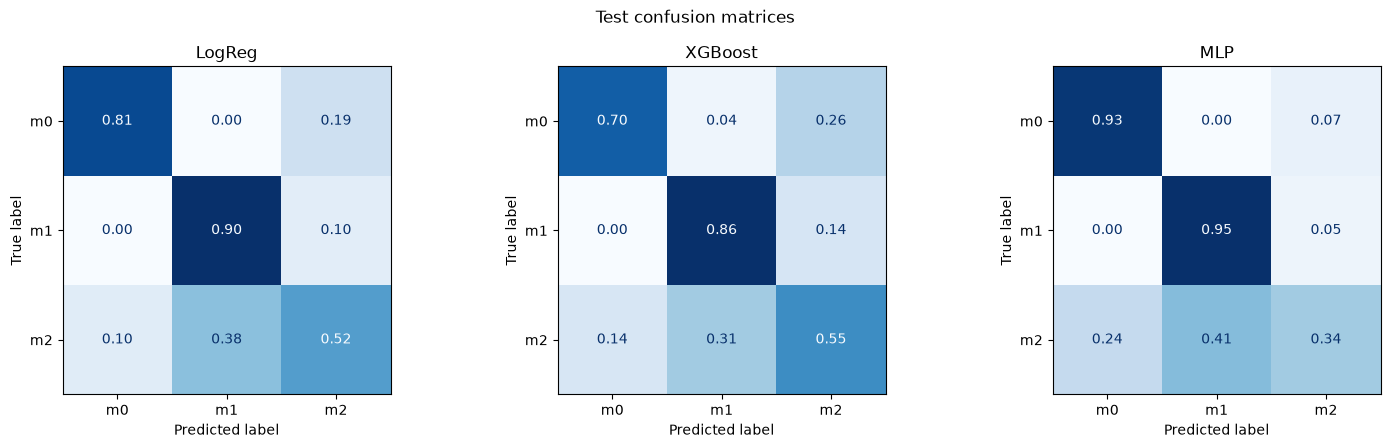

In [101]:
fig, axs = plt.subplots(ncols=len(predictions), figsize=(15, 4.5))

for ax, (name, preds) in zip(axs, predictions.items()):
  ConfusionMatrixDisplay.from_predictions(
    targets["test"], preds["test"],
    display_labels=CLASSES,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    colorbar=False,
    ax=ax,
  )
  ax.set_title(name)

fig.suptitle("Test confusion matrices")
fig.tight_layout()
plt.show()


We see that all models performed comparatively well on this data and encountered the same problem of m2 class recognition. M2 is not underrepresented, but it's located between the other two classes on the PCA, probably meaning that it blends in with M1 and M0. 

On validation set, MLP showed significantly better performance, but was overtaken by LogReg on test set. This can be a random noise from split generation, as all values are pretty close to each other and the data are limited.